## Gemma compare bf16, fp16, fp32 with new comparator

Shared-KV: прунинг Q распространяется на провайдер K/V и все его потребители. `head_dim` берётся из конкретного слоя (256/512), а не общего конфига. Несовместимые маски одной KV-семьи отклоняются.
Никакого обучения/backward в этой проверке. Полная сетка и таблица: `pruning_deviation_sweep.ipynb`.


In [1]:
import gc
import sys
import tempfile
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pruning_lens").is_dir())
sys.path.insert(0, str(ROOT))

import mlflow
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformer_lens.model_bridge import TransformerBridge
from lora_transfer_pruning.core.prune_task_type import GroupPruneTask, ModelPruneTask
from pruning_lens.usecase.compare_pruned_models_usecase import ComparePrunedModelsUsecase
from pruning_lens.core.compairing_trace_visualizer import CompairingTraceVisualizer

MODEL = "google/gemma-4-E4B-it"
DEVICE = "cuda:2"
PRECISIONS = [("BF16", torch.bfloat16), ("FP16", torch.float16)]
# FP32 — при наличии ~35 GiB свободной памяти на cuda:2; см. pruning_deviation_sweep.ipynb.

# Release model references left by the previous version of this notebook.
model = bridge = None
gc.collect()
torch.cuda.empty_cache()
SEED = 0

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL, trust_remote_code=False)
tokens = tokenizer(
    "The attention mechanism allows a language model to use information from earlier tokens.",
    return_tensors="pt",
).input_ids.to(DEVICE)


In [3]:
def load_model_and_compare_pipeline(dtype):
    model = bridge = None
    try:
        torch.manual_seed(SEED)
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, trust_remote_code=False, device_map={"": DEVICE},
            dtype=dtype, attn_implementation="eager",
        ).eval()
        bridge = TransformerBridge.boot_transformers(MODEL, hf_model=model, dtype=dtype)
        n_layers = len(bridge.blocks)
        layers = [0, n_layers // 2, n_layers - 1]  # includes shared full attention
        #layers = [0, n_layers // 2, n_layers - 1]
        
        
        mlflow.log_params({"layers": layers, "pruned_q_rows": [1, 2, 99, 125, 157, 250]})
        
        
        prune_task = ModelPruneTask({
            f"blocks.{layer}.attn.q": GroupPruneTask(cols=None, rows=[1, 2, 99, 125, 157, 250])
            for layer in layers
        })
        return ComparePrunedModelsUsecase.compare_transfer_and_torch_prunings_on_layers(
            bridge, tokens, prune_task, layers=layers, compute_gradient=True,
        )
    finally:
        # Drop both owners, collect cycles, then release unused CUDA allocations.
        del bridge, model
        gc.collect()
        torch.cuda.empty_cache()


In [4]:
import os
mlflow.set_tracking_uri("http://172.19.0.1:5000")
mlFlowClient = mlflow.MlflowClient()

from dotenv import load_dotenv

load_dotenv()

MLFLOW_EXPERIMENT = "gemma-pruning-comparator"
mlflow.set_experiment(MLFLOW_EXPERIMENT)
print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")

MLflow tracking URI: http://172.19.0.1:5000



======================== google/gemma-4-E4B-it · BF16 ========================


Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch_pruning/dependency/graph.py:390: UserWarning: Unwrapped parameters detected: ['model.vision_tower._original_component.encoder.layers.1.pre_feedforward_layernorm.weight', 'model.vision_tower._original_component.encoder.layers.7.input_layernorm.weight', 'model.language_model.layers.6._original_component.post_feedforward_layernorm._original_component.weight', 'model.audio_tower.layers.11.self_attn.relative_k_proj.weight', 'model.language_model.layers.5._original_component.pre_feedforward_layernorm._original_component.weight', 'model.language_model.layers.8._original_component.input_layernorm._original_component.weight', 'model.language_model.layers.40._original_component.post_feedforward_layernorm._original_component.weight', 'model.audio_tower.layers.3.feed_forward2.ffw_layer_1.linear.weight', 'model.vision_tower._original_component.encoder.layers.15.self_attn.q_norm.weight', 'model.language_model.layers.8._origi

[00] blocks.0.attn.q.hook_in
     FWD    OK            shape=(1, 14, 2560) compared=35840 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    DIFF          shape=(1, 14, 2560) compared=35840 max_abs=2.594e-04 mean_abs=1.256e-05 rmse=2.298e-05 rel_l2=8.396e-02 abs_l2=4.350e-03
[01] blocks.0.attn.q.hook_out
     FWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    DIFF          shape=(1, 14, 2048) compared=28672 max_abs=3.357e-04 mean_abs=7.605e-06 rmse=1.822e-05 rel_l2=8.453e-02 abs_l2=3.085e-03
[02] blocks.0.attn.hook_q
     FWD    SHAPE         shape=(1, 14, 1952) compared=0 candidate_shape=(1, 14, 2048)
     BWD    SHAPE         shape=(1, 14, 1952) compared=0 candidate_shape=(1, 14, 2048)
[03] blocks.0.attn.k.hook_in
     FWD    OK            shape=(1, 14, 2560) compared=35840 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.00

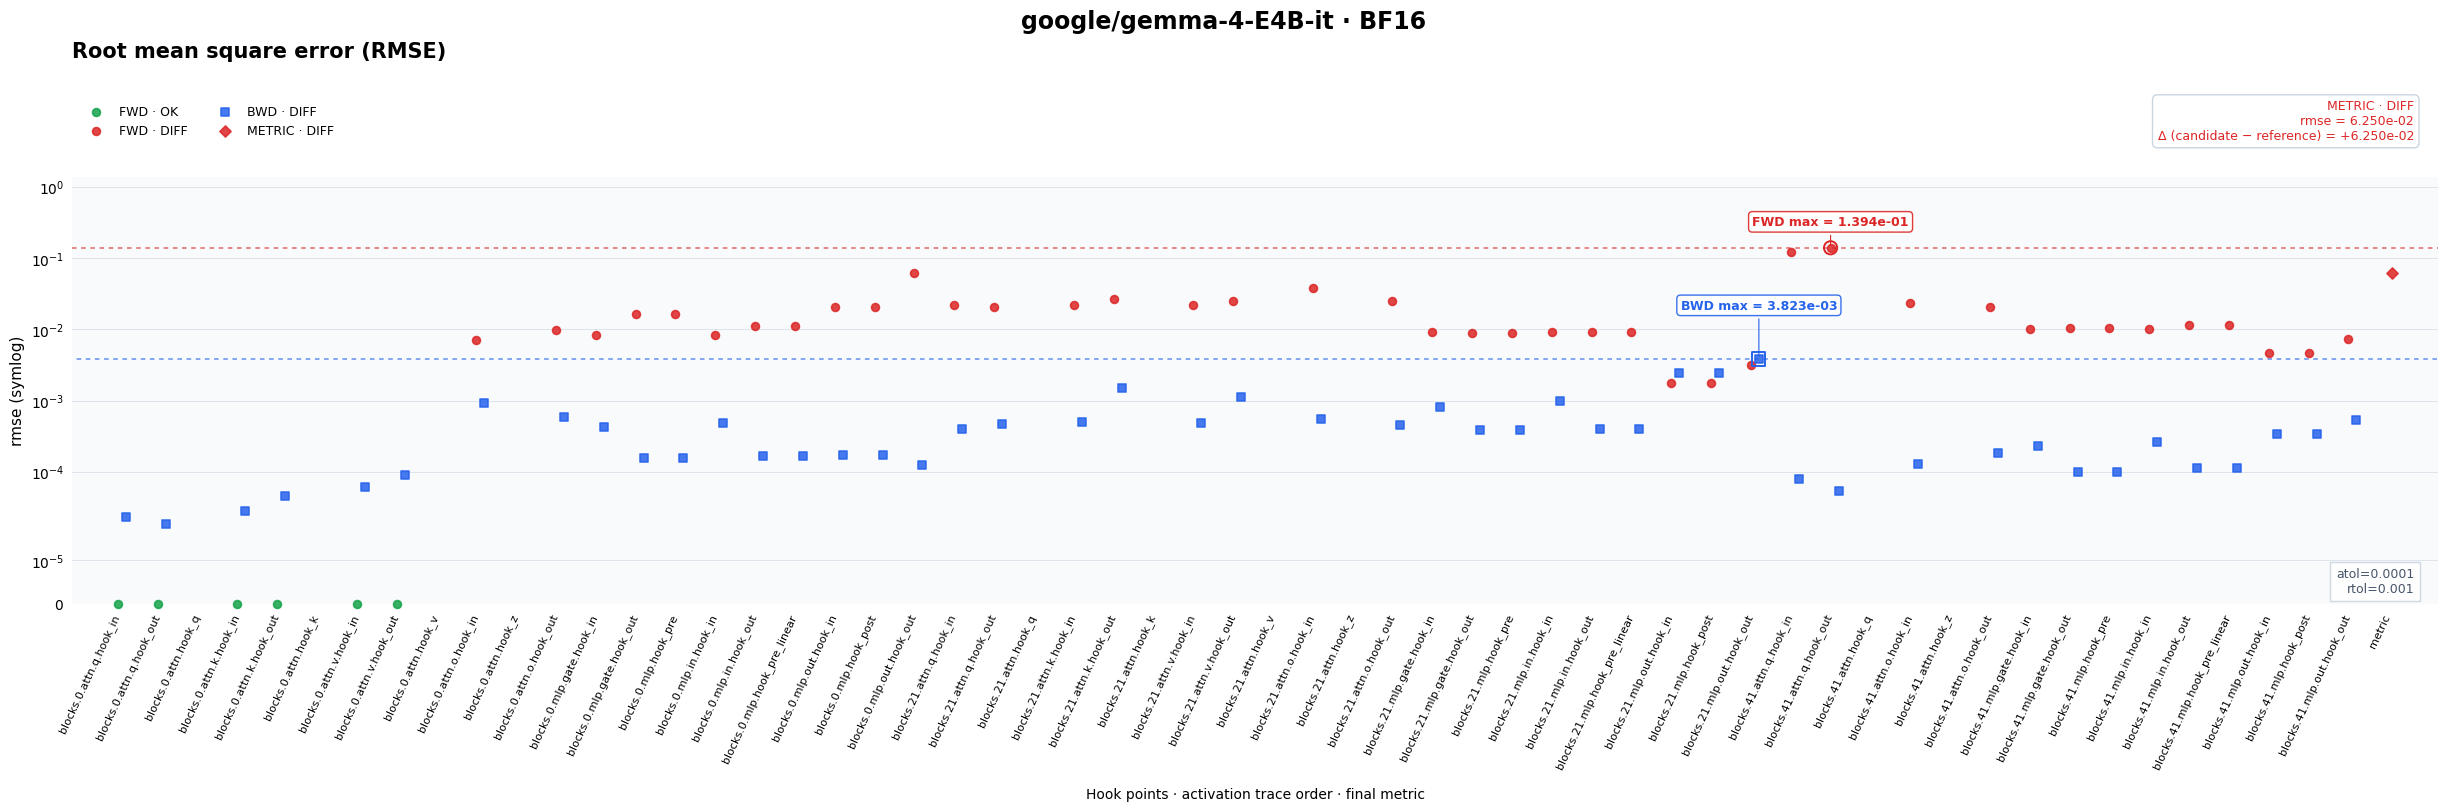

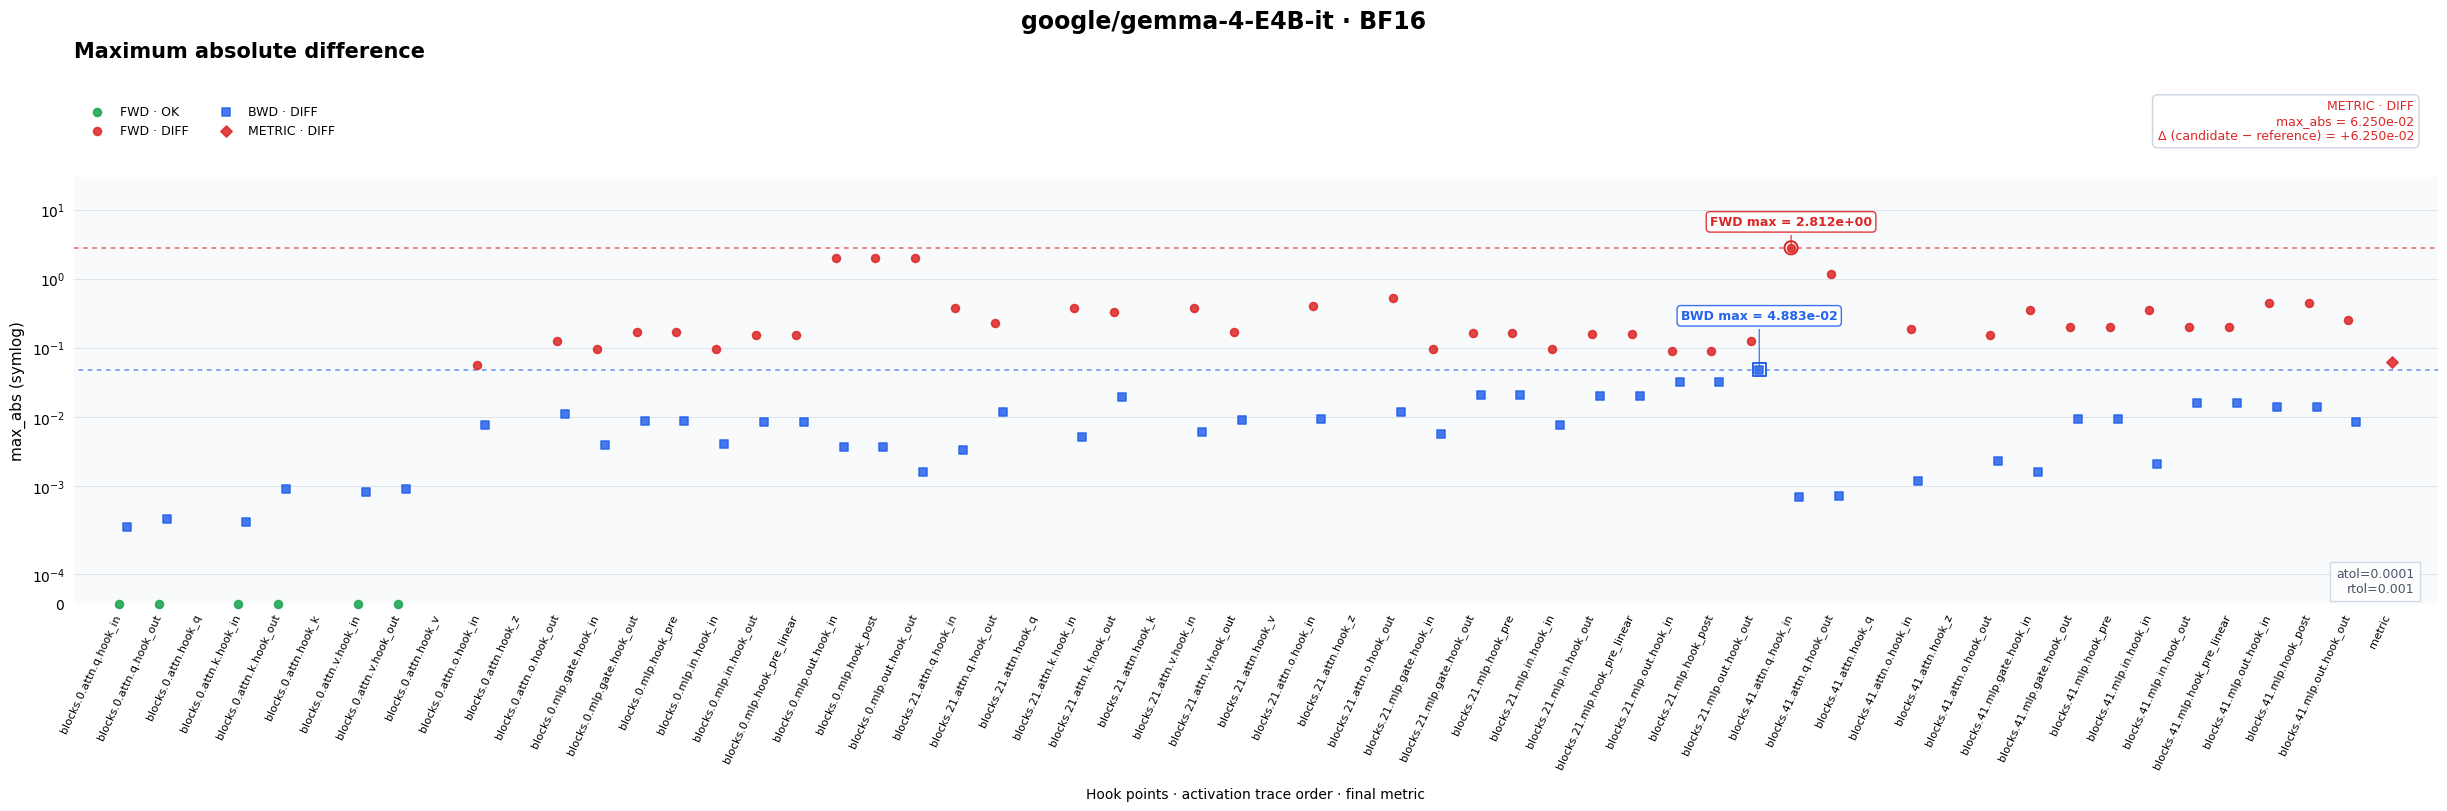

🏃 View run gemma-4-E4B-it-BF16 at: http://172.19.0.1:5000/#/experiments/77/runs/faf84c571d0946f5990e578cb55d4721
🧪 View experiment at: http://172.19.0.1:5000/#/experiments/77

======================== google/gemma-4-E4B-it · FP16 ========================


Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch_pruning/dependency/graph.py:390: UserWarning: Unwrapped parameters detected: ['model.vision_tower._original_component.encoder.layers.4.pre_feedforward_layernorm.weight', 'model.vision_tower._original_component.encoder.layers.8.self_attn.k_norm.weight', 'model.language_model.layers.40._original_component.pre_feedforward_layernorm._original_component.weight', 'model.audio_tower.layers.7.self_attn.post.linear.weight', 'model.vision_tower._original_component.encoder.layers.7.post_attention_layernorm.weight', 'model.language_model.layers.5._original_component.input_layernorm._original_component.weight', 'model.language_model.layers.13._original_component.post_attention_layernorm._original_component.weight', 'model.language_model.layers.19._original_component.post_attention_layernorm._original_component.weight', 'model.language_model.layers.37._original_component.self_attn._original_component.q_norm._original_compone

[00] blocks.0.attn.q.hook_in
     FWD    OK            shape=(1, 14, 2560) compared=35840 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    DIFF          shape=(1, 14, 2560) compared=35840 max_abs=1.202e-04 mean_abs=5.683e-06 rmse=1.123e-05 rel_l2=4.337e-02 abs_l2=2.125e-03
[01] blocks.0.attn.q.hook_out
     FWD    OK            shape=(1, 14, 2048) compared=28672 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.000e+00 abs_l2=0.000e+00
     BWD    DIFF          shape=(1, 14, 2048) compared=28672 max_abs=1.802e-04 mean_abs=3.296e-06 rmse=8.631e-06 rel_l2=4.251e-02 abs_l2=1.462e-03
[02] blocks.0.attn.hook_q
     FWD    SHAPE         shape=(1, 14, 1952) compared=0 candidate_shape=(1, 14, 2048)
     BWD    SHAPE         shape=(1, 14, 1952) compared=0 candidate_shape=(1, 14, 2048)
[03] blocks.0.attn.k.hook_in
     FWD    OK            shape=(1, 14, 2560) compared=35840 max_abs=0.000e+00 mean_abs=0.000e+00 rmse=0.000e+00 rel_l2=0.00

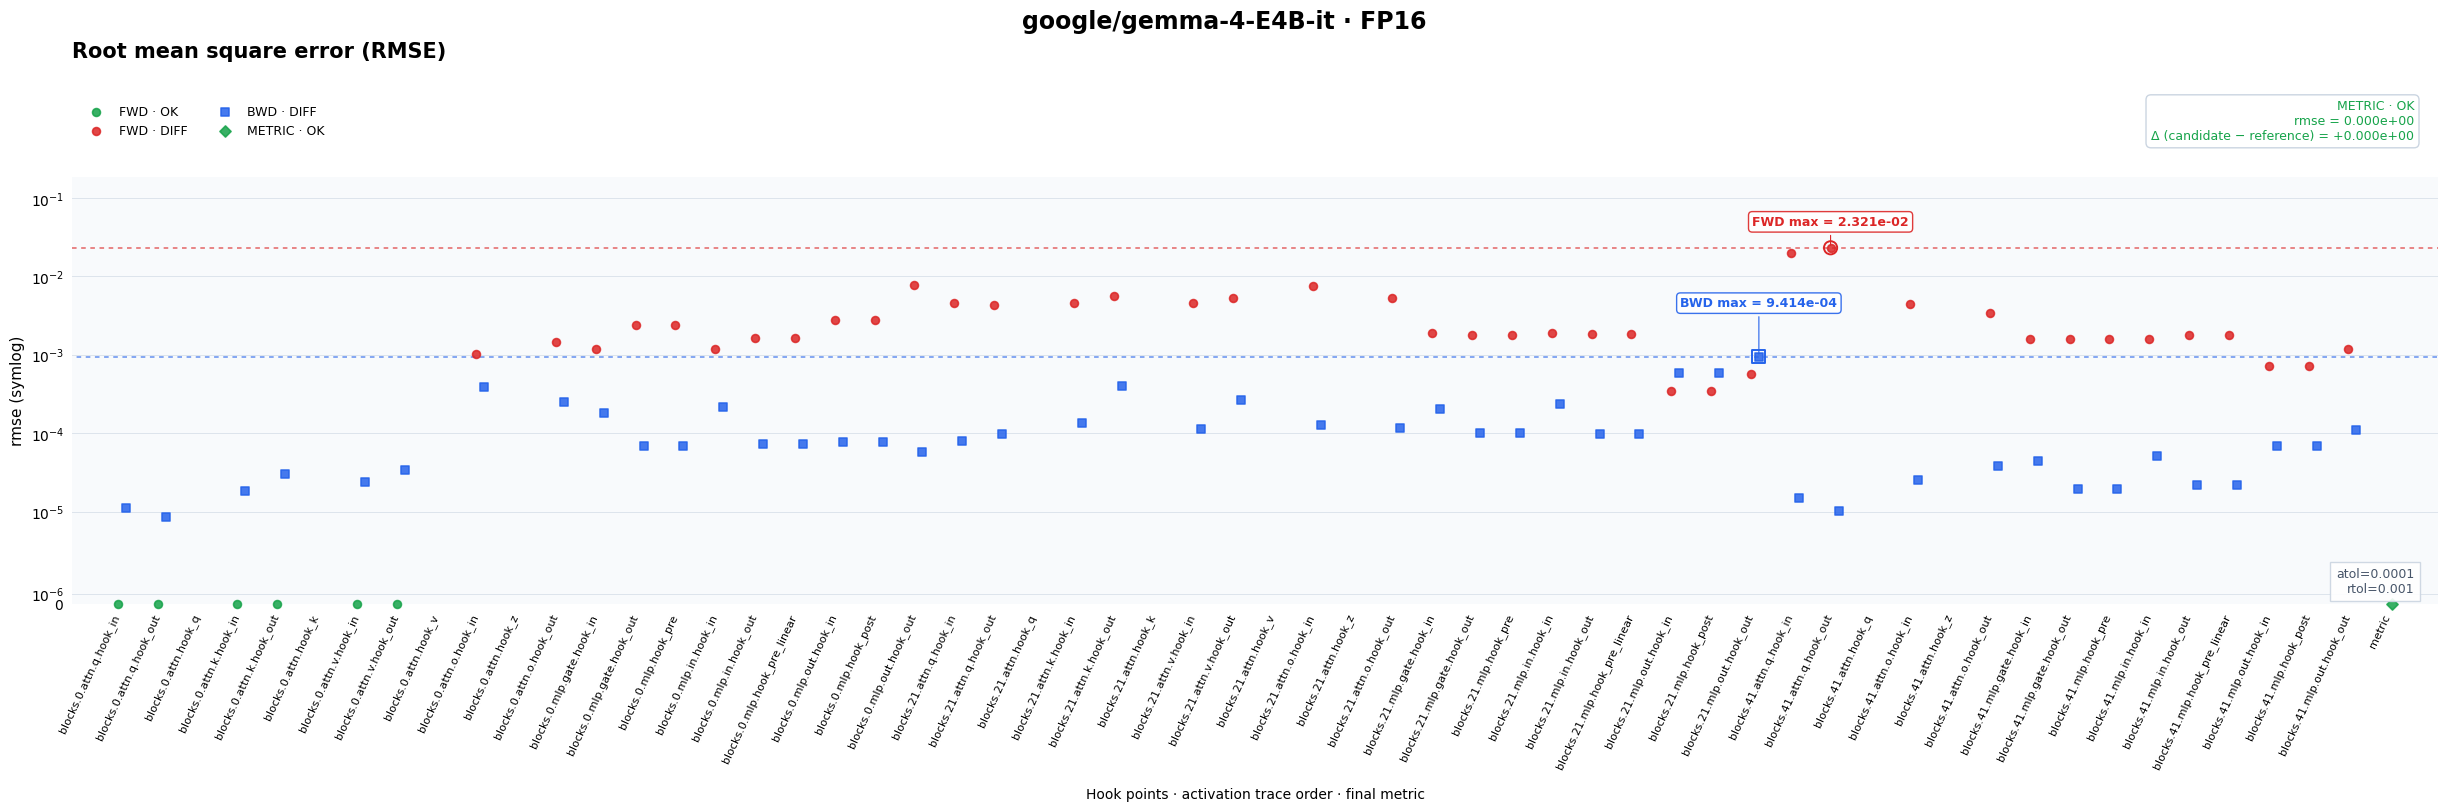

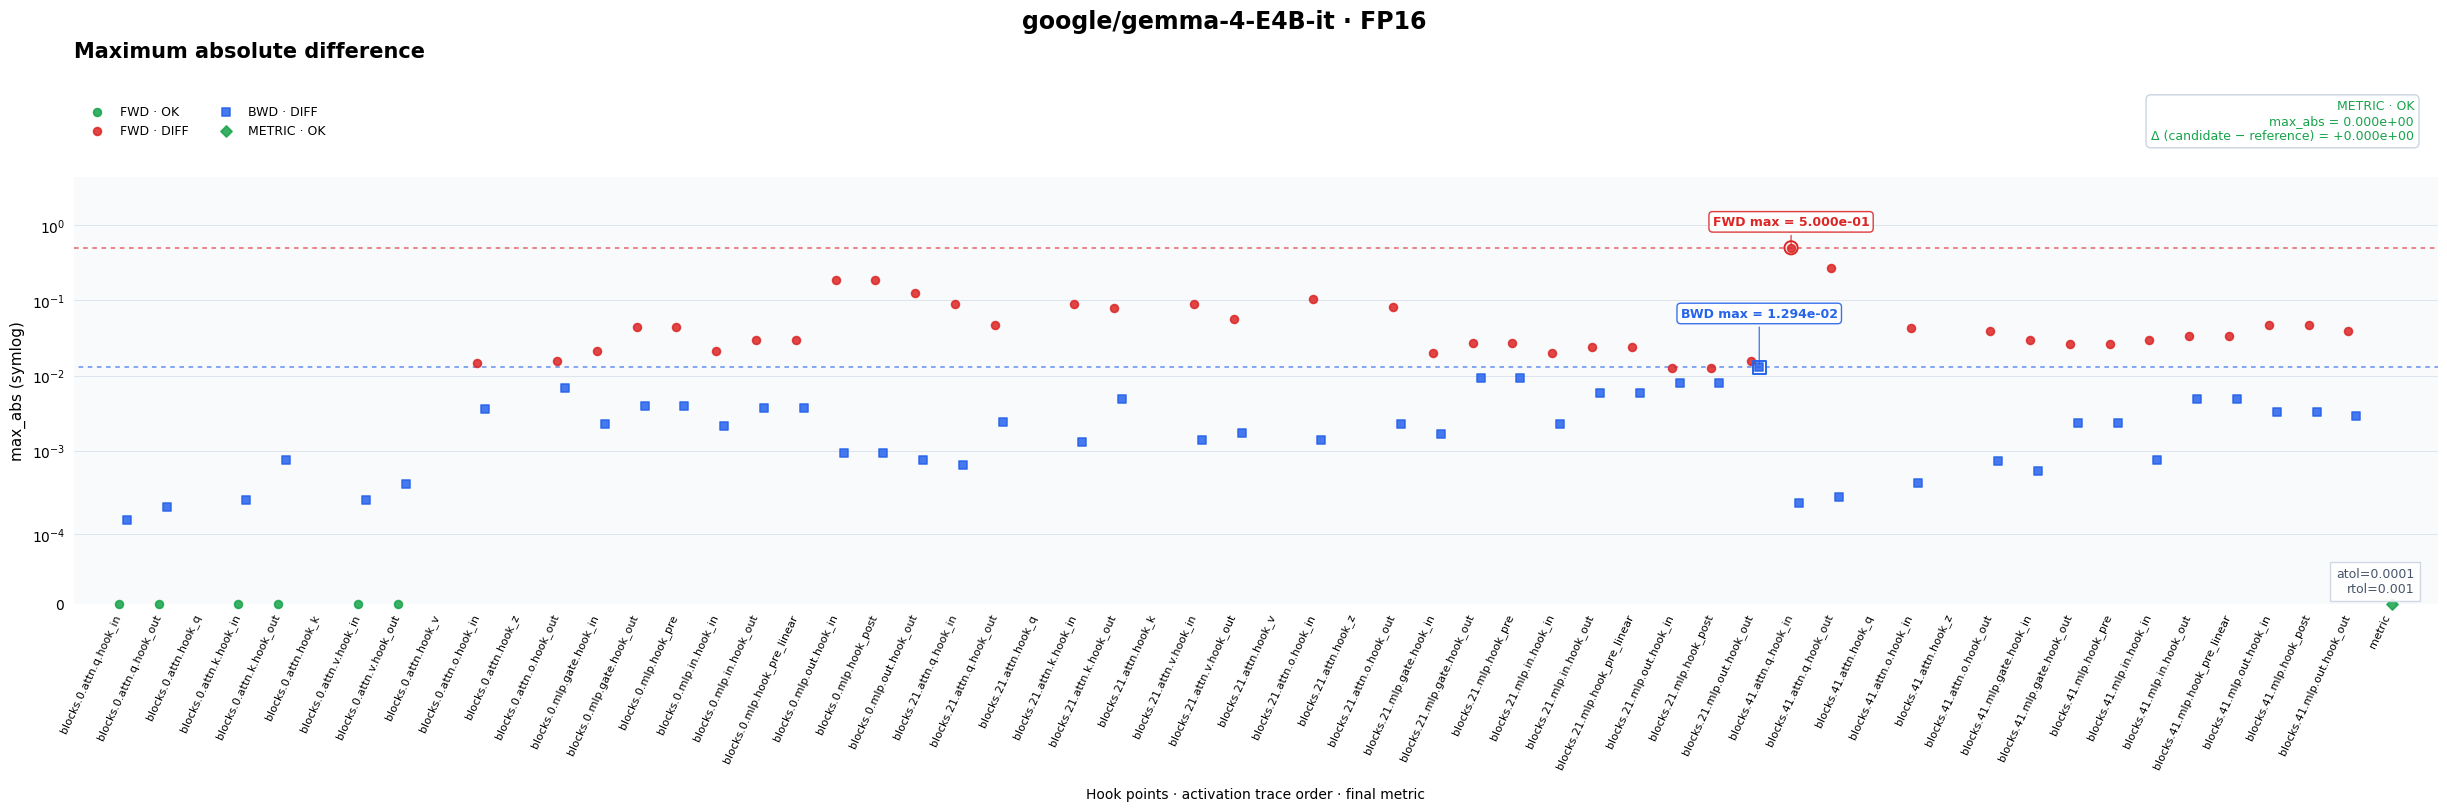

🏃 View run gemma-4-E4B-it-FP16 at: http://172.19.0.1:5000/#/experiments/77/runs/dd8b100eb0e0494abb1ce2ca0619be57
🧪 View experiment at: http://172.19.0.1:5000/#/experiments/77


In [5]:
results = {}
for precision, dtype in PRECISIONS:
    print(f"\n{'=' * 24} {MODEL} · {precision} {'=' * 24}")
    with mlflow.start_run(run_name=f"{MODEL.rsplit('/', 1)[-1]}-{precision}") as run:
        mlflow.log_params({
            "model": MODEL,
            "precision": precision,
            "seed": SEED,
            "compute_gradient": False,
            "attn_implementation": "eager",
        })
        compairing_trace, sim_prune_trace, tp_trace = load_model_and_compare_pipeline(dtype)
        results[precision] = {
            "comparison": compairing_trace,
            "sim_prune_trace": sim_prune_trace,
            "tp_trace": tp_trace,
        }
        mlflow.log_params({
            "compairing_trace.atol": compairing_trace.atol,
            "compairing_trace.rtol": compairing_trace.rtol,
        })
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "result.pt"
            torch.save({
                **results[precision],
            }, path)
            
            artifact_path="pruning_traces"
            mlflow.log_artifact(str(path), artifact_path="traces")
        print(f"Saved: s3://mlflow/{run.info.experiment_id}/runs/{run.info.run_id}/artifact/traces/result.pt")

        figures = CompairingTraceVisualizer.plot_metrics(
            compairing_trace, ["rmse", "max_abs"], title=f"{MODEL} · {precision}",
        )
        try:
            pass
            for name, figure in figures.items():
                mlflow.log_figure(figure, f"figures/{name}.png")
        finally:
            for figure in figures.values():
                plt.close(figure)
